# ロボットは、日常会話や複雑な指示でも物を運べるか

## 目的

ロボットへの指示は、「青いブロックを黄色い皿に置いて」のようにはっきり言う場合もあれば、日常会話のようにくだけて曖昧に言う場合もあり、「左から3番目のブロック」のように複雑に言う場合もある。指示の言い方によって、ロボットが正しく動けるかどうかが変わるのかを調べる。

## 方法

シミュレータの中で、ロボットアーム（Franka）に、机の上のブロックを掴んで皿に置かせる。

- 指示を理解する部分には Gemini Robotics-ER（以下 ER）を使う。シミュレータの真上の画像と指示文を渡し、「どのブロックを」「どの皿に」を、画像上の点で答えてもらう。
- その点を机の上の座標に直し、逆運動学で腕を動かして、掴む・運ぶ・置くを実行する。
- 掴む動作は物理演算（摩擦や接触）で決まる。ER が正しい点を答えても、掴めないことがある。
- 成功は、正しいブロックが正しい皿の上に載ること。

画像と目標（どのブロックをどの皿へ）は固定して、指示だけを次の3種類に変え、成功率を比べる。

| 種類 | 内容 | 例 |
|---|---|---|
| 普通の指示 | 色ではっきり言う | 青いブロックを黄色い皿に置いて。 |
| 日常会話の指示 | 方言、指示語、言い直しなどを含む話し言葉 | 黄色い皿が空いてるから、そこに青いブロックを運んどいて。 |
| 複雑な指示 | 順序・相対位置・除外・距離で指す | 左から3番目のブロックを黄色い皿に置いて。 |

日常会話の指示は5種類の言い回し、複雑な指示は4種類の指し方を使う。


## 1. 準備

In [1]:
%pip install -U -q google-genai

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.0 which is incompatible.


In [2]:
from google.colab import userdata

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

In [3]:
from google import genai
from google.genai import types

client = genai.Client(api_key=GEMINI_API_KEY)

In [4]:
import re
import time
from google.genai import errors

MIN_INTERVAL = 13.0   # 無料枠 5リクエスト/分 → 12秒超の間隔を確保
MAX_RETRIES = 6
_last_call = 0.0

# 再実行しても二重ラップにならないよう、クラスから元のメソッドを取得
_orig_generate_content = client.models.__class__.generate_content.__get__(client.models)

def _retry_delay(e):
    m = re.search(r"retry in ([\d.]+)s", str(e)) or re.search(r"'retryDelay': '([\d.]+)s'", str(e))
    return float(m.group(1)) + 1 if m else None

def _rate_limited_generate_content(*args, **kwargs):
    global _last_call
    for attempt in range(MAX_RETRIES + 1):
        wait = MIN_INTERVAL - (time.time() - _last_call)
        if wait > 0:
            time.sleep(wait)
        _last_call = time.time()
        try:
            return _orig_generate_content(*args, **kwargs)
        except errors.APIError as e:
            code = getattr(e, "code", None)
            if code == 429 and "PerDay" in str(e):
                raise RuntimeError("1日の上限に到達しました。翌日に再実行するか課金を有効にしてください。") from e
            if code in (429, 500, 503) and attempt < MAX_RETRIES:
                d = _retry_delay(e) or 20 * (attempt + 1)
                print(f"[retry {attempt+1}/{MAX_RETRIES}] code={code}, {d:.0f}秒待機")
                time.sleep(d)
                continue
            raise

client.models.generate_content = _rate_limited_generate_content

In [5]:
MODEL_ID = "gemini-robotics-er-2-preview"

In [6]:
%pip install -q mujoco imageio imageio-ffmpeg

In [7]:
import os, subprocess
os.environ["MUJOCO_GL"] = "egl"            # GPUランタイムでのオフスクリーン描画（mujoco の import より前に設定）
os.environ["PYOPENGL_PLATFORM"] = "egl"
subprocess.run("apt-get -qq update && apt-get -qq install -y libegl1 libgl1 libglu1-mesa fonts-noto-cjk",
               shell=True, check=False, capture_output=True)

MENAGERIE = "/content/mujoco_menagerie"
if not os.path.exists(MENAGERIE):
    subprocess.run(["git", "clone", "-q", "--depth", "1",
                    "https://github.com/google-deepmind/mujoco_menagerie.git", MENAGERIE], check=True)
PANDA_DIR = MENAGERIE + "/franka_emika_panda"
print(sorted(os.listdir(PANDA_DIR)))

['CHANGELOG.md', 'LICENSE', 'README.md', 'assets', 'hand.xml', 'mjx_hand.xml', 'mjx_panda.xml', 'mjx_panda_nohand.xml', 'mjx_scene.xml', 'mjx_single_cube.xml', 'panda.png', 'panda.xml', 'panda_nohand.xml', 'scene.xml']


In [8]:
import json
import textwrap
import io
import math, functools
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageFont
from IPython.display import display, Video

In [9]:
def parse_json(json_output):
  # Parsing out the markdown fencing
  lines = json_output.splitlines()
  for i, line in enumerate(lines):
    if line == "```json":
      # Remove everything before "```json"
      json_output = "\n".join(lines[i + 1 :])
      # Remove everything after the closing "```"
      json_output = json_output.split("```")[0]
      break  # Exit the loop once "```json" is found
  return json_output

In [10]:
def call_gemini_robotics_er(img, prompt, config=None):
    default_config = types.GenerateContentConfig(
        temperature=1.0,
        thinking_config=types.ThinkingConfig(thinking_budget=0)
    )

    if config is None:
        config = default_config

    image_response = client.models.generate_content(
          model=MODEL_ID,
          contents=[img, prompt],
          config=config,
    )

    return parse_json(image_response.text)

## 2. 実験の設定

In [28]:
SESSION = "run04"        # 実験ごとに変える。保存先（Drive）が分かれ、前の実験の結果は上書きされない
USE_DRIVE = True         # Google Drive に保存する（ランタイムが切れても残る）
N_SCENES = 3             # シーンの数。API の回数は「3種類 × シーン数 × REPS」
REPS = 1                 # 同じ指示を何回 ER に聞くか
THINKING_BUDGET = 0      # 0 は思考なし
ORACLE_MIN = 0.9         # 正解の座標での成功率がこれ未満のシーンは使わない
LIGHT_TARGET = 0.975      # 画像の明るさの目標（本来の色に対する比。1 に近いほど白飛びしない）
EPISODES_PER_VIDEO = 4   # 動画1本に入れる目標の数
SHOW_VIDEOS = True       # False にすると、動画をノートブックに埋め込まない（ファイルは保存される）
SCENE_CANDIDATES = list(range(0, 80))   # シーンの候補。この中から、物理的に成立するものを順に選ぶ

## 3. シーンと指示文

画像には、ブロック8個と皿3枚を置く。ブロックは立方体と円柱が混ざり、青と水色、緑と黄緑、赤とピンクとオレンジのような似た色が必ず含まれる。皿のうち2枚は、ブロックと同じ色にしてある。

1つのシーンに目標を10個作り、同じ目標を3種類の言い方で指示する。目標は、複雑な指示で答えが1つに決まるものだけを使う。「左から何番目」が曖昧にならないよう、隣のブロックとの間隔に条件をつけ、「右隣」や「一番近い」も、人が見て1つに決まるものだけにした。

ここでは、物理シミュレータを使わずに、指示文の自動チェックと一覧を出す。

In [29]:
import math, random, functools, os, json, time, hashlib, collections
from dataclasses import dataclass
import numpy as np

GEOM_VERSION = "A-8b3p-types-v1"   # シーンの作り方を変えたら更新する（セッションの設定照合に使う）

# ---------- 色（10色）。紛らわしい色の組は、必ずブロックに同居させる ----------
COLORS = {"赤": (215, 40, 40), "青": (30, 70, 215), "緑": (30, 150, 60), "黄": (245, 215, 40),
          "水色": (130, 210, 245), "オレンジ": (245, 140, 30), "ピンク": (245, 140, 190),
          "紫": (130, 60, 170), "茶": (120, 75, 40), "黄緑": (160, 210, 50)}
CONFUSABLE = ["青", "水色", "緑", "黄緑", "赤", "ピンク", "オレンジ"]   # 青/水色・緑/黄緑・赤/ピンク/オレンジ
N_BLOCKS, N_PLATES, N_SHARED, N_TARGETS = 8, 3, 2, 10
BLOCK_H = 0.02          # ブロックの半サイズ [m]（一辺4cm）
PLATE_R = 0.055         # 皿の半径 [m]
WORK_X = (0.34, 0.66)   # ロボットの前方 [m]
WORK_Y = (-0.30, 0.30)  # 左右 [m]（+Y が画像の左）

# ---------- ER に見せる真上カメラ（XMLもこの値から作る）----------
TOP_POS = np.array([0.50, 0.0, 0.90])
TOP_FOVY = 34.0
IMG_W, IMG_H = 640, 400
_F = (IMG_H / 2) / math.tan(math.radians(TOP_FOVY) / 2)

def world_to_pixel(X, Y, Z=0.0):
    d = TOP_POS[2] - Z
    return IMG_W / 2 - (Y - TOP_POS[1]) * _F / d, IMG_H / 2 - (X - TOP_POS[0]) * _F / d

def pixel_to_world(u, v, Z=0.0):
    d = TOP_POS[2] - Z
    return TOP_POS[0] + (IMG_H / 2 - v) * d / _F, TOP_POS[1] - (u - IMG_W / 2) * d / _F

@dataclass
class Obj:
    kind: str       # "block" or "plate"
    color: str
    X: float
    Y: float
    shape: str      # block: cube / cylinder、plate: plate
    @property
    def x(self): return -self.Y
    @property
    def y(self): return -self.X
    @property
    def r(self): return PLATE_R if self.kind == "plate" else BLOCK_H

_NEED = {("block", "block"): 0.10, ("plate", "block"): 0.115,
         ("block", "plate"): 0.115, ("plate", "plate"): 0.14}

def _try_layout(rng):
    """案A: ブロック8個（紛らわしい7色＋1色）、皿3枚（うち2枚はブロックと同じ色）"""
    others = [c for c in COLORS if c not in CONFUSABLE]       # 黄・紫・茶
    extra = rng.choice(others)
    bcols = CONFUSABLE + [extra]
    free = [c for c in others if c != extra]
    shared = rng.sample(CONFUSABLE, N_SHARED)                  # 皿がブロックと共有する色
    pcols = shared + [rng.choice(free)]
    rng.shuffle(bcols)
    plan = [("plate", c) for c in pcols] + [("block", c) for c in bcols]
    objs = []
    for kind, c in plan:
        for _ in range(400):
            X, Y = rng.uniform(*WORK_X), rng.uniform(*WORK_Y)
            if all(math.hypot(X - o.X, Y - o.Y) >= _NEED[(kind, o.kind)] for o in objs):
                break
        else:
            return None
        shape = rng.choice(["cube", "cylinder"]) if kind == "block" else "plate"
        objs.append(Obj(kind, c, X, Y, shape))
    return objs

# ---------- 目標（どのブロックを、どの皿に）----------
# 目標は「複雑な指示」で一意に指せるブロックから選ぶ。同じ目標を、3種類の言い方で指示する。
KIND_DESC = {1: "普通の指示", 2: "日常会話の指示", 3: "複雑な指示"}
KIND_KEYS = [1, 2, 3]
CAT_DESC = {"ordinal": "順序（左から3番目など）", "relative": "相対位置（〜の右隣など）",
            "exclude": "除外（〜以外で一番左など）", "near": "距離（皿に一番近い）"}
COUNTS = {"ordinal": 3, "relative": 3, "exclude": 2, "near": 2}      # 1シーンの目標の内訳（計10）
GAP = 0.05                      # 「左から◯番目」が曖昧にならないための、隣のブロックとの横の間隔 [m]

TEMPLATE_KEYS = ["t3", "tS", "t6", "t7", "t8"]
TEMPLATE_DESC = {"t3": "確認＋それ/あっち", "tS": "状況説明＋そこ", "t6": "名詞の省略",
                 "t7": "言い直し", "t8": "位置のぼかし＋やつ"}
WRONG_PARTNER = {"青": "水色", "水色": "青", "緑": "黄緑", "黄緑": "緑", "赤": "ピンク", "ピンク": "赤",
                 "オレンジ": "赤", "黄": "オレンジ", "紫": "青", "茶": "オレンジ"}   # 言い間違えやすい色

def _d(a, b):
    return math.hypot(a.x - b.x, a.y - b.y)

def _region(blk):
    return "左のほう" if blk.Y > 0.10 else ("右のほう" if blk.Y < -0.10 else "真ん中あたり")

def _rel_candidates(bl):
    """(基準ブロック, 向き, 対象ブロック)。「〜の右隣」が一意に決まるものだけ"""
    out = []
    for ref in bl:
        nearest = min((o for o in bl if o is not ref), key=lambda o: _d(o, ref))
        for side, sgn in (("right", 1), ("left", -1)):
            cand = [o for o in bl if o is not ref and sgn * (o.x - ref.x) > 0
                    and abs(o.y - ref.y) < abs(o.x - ref.x)]
            if not cand:
                continue
            cand.sort(key=lambda o: _d(o, ref))
            if cand[0] is not nearest:
                continue                                   # 隣は、一番近いブロックでなければならない
            if len(cand) > 1 and _d(cand[1], ref) < 1.3 * _d(cand[0], ref):
                continue                                   # 2番手と近すぎると曖昧
            out.append((ref, side, cand[0]))
    return out

def _structural_pool(blocks, plates):
    """複雑な指示で、一意に指せるブロックの候補（種類ごと）。(参照の情報, 対象ブロック) のリスト"""
    srt = sorted(blocks, key=lambda o: o.x)                # 画像の左→右
    def gap_ok(i):
        return (i == 0 or srt[i].x - srt[i - 1].x >= GAP) and (i == len(srt) - 1 or srt[i + 1].x - srt[i].x >= GAP)
    pool = {k: [] for k in COUNTS}
    for side in ("left", "right"):
        for k in (2, 3, 4, 5):
            i = k - 1 if side == "left" else len(srt) - k
            if gap_ok(i):
                pool["ordinal"].append((("ordinal", side, k), srt[i]))
    for ref, side, t in _rel_candidates(blocks):
        pool["relative"].append((("rel", side, ref.color), t))
    for side in ("left", "right"):                         # 端から2つを除いて、3番目を指す
        s2 = sorted(blocks, key=lambda o: o.x, reverse=(side == "right"))
        if gap_ok(srt.index(s2[2])):
            pool["exclude"].append((("excl", side, s2[0].color, s2[1].color), s2[2]))
    for w in plates:
        ds = sorted(blocks, key=lambda o: _d(o, w))
        if _d(ds[1], w) >= 1.25 * _d(ds[0], w):
            pool["near"].append((("near", w.color), ds[0]))
    return pool

def _pick(pool, rng):
    chosen = []
    for cat, n in COUNTS.items():
        items = pool[cat][:]; rng.shuffle(items)
        seen, picked = set(), []
        for ref, t in items:
            if t.color in seen or (cat == "relative" and any(ref[2] == p[0][2] for p in picked)):
                continue                                   # 同じ種類の中で、対象や基準が重ならないようにする
            picked.append((ref, t)); seen.add(t.color)
            if len(picked) == n:
                break
        if len(picked) < n:
            return None
        chosen += [(cat, ref, t) for ref, t in picked]
    return chosen

def _make_targets(objs, rng):
    blocks = [o for o in objs if o.kind == "block"]
    plates = [o for o in objs if o.kind == "plate"]
    plate_cols = [o.color for o in plates]
    shared = set(plate_cols) & {b.color for b in blocks}   # 皿と同じ色のブロック
    pool = _structural_pool(blocks, plates)
    if any(len(pool[c]) < n for c, n in COUNTS.items()):
        return None
    for _ in range(50):
        chosen = _pick(pool, rng)
        if chosen and sum(t.color in shared for _, _, t in chosen) >= 2:
            break                                          # 皿と同じ色のブロックを、2件以上含める
    else:
        return None
    rng.shuffle(chosen)
    slots = TEMPLATE_KEYS * (len(chosen) // len(TEMPLATE_KEYS))
    for _ in range(3000):
        rng.shuffle(slots)
        # 名詞を省く型（t6, t8）には、皿と同じ色のブロックの目標を入れる（本当に紛らわしくなる）
        if all(any(chosen[i][2].color in shared for i, s in enumerate(slots) if s == k) for k in ("t6", "t8")):
            break
    else:
        return None
    targets, used = [], set()
    for i, ((cat, ref, t), tmpl) in enumerate(zip(chosen, slots)):
        c = t.color
        ban = {c} | ({ref[1]} if cat == "near" else set())    # 自分と同じ色の皿、「一番近い」の基準の皿は置き先にしない
        cand = [p for p in plate_cols if p not in ban and (c, p) not in used]
        if not cand:
            return None
        tp = rng.choice(cand)
        used.add((c, tp))
        targets.append({"idx": i + 1, "cat": cat, "ref": ref, "tb": c, "tw": tp, "tmpl": tmpl,
                        "region": _region(t), "wrong": WRONG_PARTNER[c]})
    return targets

@functools.lru_cache(maxsize=None)
def get_scene(seed):
    rng = random.Random(seed)
    for _ in range(300000):
        objs = _try_layout(rng)
        if not objs:
            continue
        targets = _make_targets(objs, rng)
        if targets:
            return objs, targets
    raise ValueError("シーン生成に失敗しました")

# ---------- 日本語の言い回し（「皿」に統一）----------
CJ = {"赤": "赤い", "青": "青い", "緑": "緑色の", "黄": "黄色い", "水色": "水色の",
      "オレンジ": "オレンジ色の", "ピンク": "ピンク色の", "紫": "紫色の", "茶": "茶色の", "黄緑": "黄緑色の"}
SIDE_JA = {"left": "左", "right": "右"}
def blk(c): return f"{CJ[c]}ブロック"
def pl(c):  return f"{CJ[c]}皿"
def pro(c):                         # 名詞を省いた言い方（青いの / 緑色のやつ）
    a = CJ[c]
    return a + "の" if a.endswith("い") else a + "やつ"

def _complex_ref(ref):
    t = ref[0]
    if t == "ordinal": return f"{SIDE_JA[ref[1]]}から{ref[2]}番目のブロック"
    if t == "rel":     return f"{CJ[ref[2]]}ブロックの{SIDE_JA[ref[1]]}隣のブロック"
    if t == "excl":    return f"{CJ[ref[2]]}ブロックと{CJ[ref[3]]}ブロック以外で、一番{SIDE_JA[ref[1]]}のブロック"
    if t == "near":    return f"{CJ[ref[1]]}皿に一番近いブロック"
    raise ValueError(ref)

def _talk(t):
    """日常会話の指示（5つの型）"""
    c, p, w, k = t["tb"], t["tw"], t["wrong"], t["tmpl"]
    if k == "t3": return f"{blk(c)}あるやろ。それをあっちの{pl(p)}に頼むわ。"
    if k == "tS": return f"{pl(p)}が空いてるから、そこに{blk(c)}を運んどいて。"
    if k == "t6": return f"なあなあ、{pro(c)}、{pro(p)}にのせといてくれへん？"
    if k == "t7": return f"{blk(w)}を…あ、ごめん、{blk(c)}を{pl(p)}に移動させて。"
    if k == "t8": return f"{t['region']}にある{CJ[c]}やつ、{pl(p)}にやっといて。"
    raise ValueError(k)

def instruction(t, kind):
    """kind 1: 普通の指示（色で指定）/ 2: 日常会話の指示 / 3: 複雑な指示（順序・相対位置・除外・距離）"""
    if kind == 1:
        return f"{blk(t['tb'])}を{pl(t['tw'])}に置いて。"
    if kind == 2:
        return _talk(t)
    return f"{_complex_ref(t['ref'])}を{pl(t['tw'])}に置いて。"

PROMPT_TMPL = """You control a robot arm. The image is a top-down view of a table.
There are small blocks (cubes or cylinders) and larger flat plates (discs).
Each numbered instruction below is an independent request written in Japanese; do not use information from other instructions.
For each instruction, identify the block to pick up and the plate to place it on.
Point to the center of the block and the center of the plate.
Directions such as left and right are as seen in the image.

Instructions:
{instructions}

Return a JSON list with exactly one object per instruction, in the same order:
[{{"id": 1, "block": {{"point": <point>, "label": <label>}}, "plate": {{"point": <point>, "label": <label>}}}}, ...]
The points are in [y, x] format normalized to 0-1000."""

def build_prompt(targets, kind):
    lines = "\n".join(f"{i}. {instruction(t, kind)}" for i, t in enumerate(targets, 1))
    return PROMPT_TMPL.format(instructions=lines)

def parse_batch(text, k):
    """モデルの出力 -> {id: {"block": [y,x], "plate": [y,x]}}。読めなかった id は含まれない"""
    try:
        d = json.loads(text)
    except Exception:
        return {}
    if isinstance(d, dict):
        lists = [v for v in d.values() if isinstance(v, list)]
        d = lists[0] if lists else [d]
    out = {}
    for pos, it in enumerate(d):
        try:
            i = int(it.get("id", pos + 1))
            b, w = it["block"]["point"], it["plate"]["point"]
            assert len(b) == 2 and len(w) == 2
            out[i] = {"block": [float(b[0]), float(b[1])], "plate": [float(w[0]), float(w[1])]}
        except Exception:
            continue
    return {i: v for i, v in out.items() if 1 <= i <= k}

def oracle_preds(objs, targets):
    """正解の座標を、ER の出力と同じ形式（0-1000の[y, x]）にしたもの"""
    by = {(o.kind, o.color): o for o in objs}
    out = {}
    for i, t in enumerate(targets, 1):
        b, p = by[("block", t["tb"])], by[("plate", t["tw"])]
        ub, vb = world_to_pixel(b.X, b.Y, BLOCK_H)
        up, vp = world_to_pixel(p.X, p.Y, 0.0)
        out[i] = {"block": [vb / IMG_H * 1000, ub / IMG_W * 1000],
                  "plate": [vp / IMG_H * 1000, up / IMG_W * 1000]}
    return out

def validate_instructions(seeds):
    """指示文と目標の自動チェック。問題があれば AssertionError"""
    for s in seeds:
        objs, tg = get_scene(s)
        blocks = {o.color: o for o in objs if o.kind == "block"}
        plates = {o.color: o for o in objs if o.kind == "plate"}
        bl = list(blocks.values())
        pix = {c: world_to_pixel(o.X, o.Y, 0.0) for c, o in blocks.items()}    # 画像上の位置で、別経路の検算
        assert len(tg) == sum(COUNTS.values()) and len(blocks) == N_BLOCKS and len(plates) == N_PLATES
        assert collections.Counter(t["cat"] for t in tg) == collections.Counter(COUNTS)
        assert all(v == len(tg) // len(TEMPLATE_KEYS) for v in collections.Counter(t["tmpl"] for t in tg).values())
        assert set(CONFUSABLE) <= set(blocks) and len(set(plates) & set(blocks)) == N_SHARED
        assert len({(t["tb"], t["tw"]) for t in tg}) == len(tg)
        for t in tg:
            c, p, ref, k = t["tb"], t["tw"], t["ref"], t["tmpl"]
            assert c in blocks and p in plates and c != p
            assert t["wrong"] in blocks and t["wrong"] != c and t["region"] == _region(blocks[c])
            # 複雑な指示が、本当に対象を一意に指しているか
            order = sorted(blocks, key=lambda x: pix[x][0])                    # 画像の左→右
            if ref[0] == "ordinal":
                assert (order[ref[2] - 1] if ref[1] == "left" else order[-ref[2]]) == c
            if ref[0] == "excl":
                rest = [x for x in order if x not in ref[2:]]
                assert (rest[0] if ref[1] == "left" else rest[-1]) == c
            if ref[0] == "near":
                w = plates[ref[1]]
                assert min(bl, key=lambda o: math.hypot(o.X - w.X, o.Y - w.Y)).color == c and p != ref[1]
            if ref[0] == "rel":
                r = blocks[ref[2]]; du = pix[c][0] - pix[ref[2]][0]; dv = pix[c][1] - pix[ref[2]][1]
                assert (du > 0) == (ref[1] == "right") and abs(dv) < abs(du)
            # 3種類の指示文
            a, b, d = (instruction(t, K) for K in KIND_KEYS)
            assert "ブロック" in a and "皿" in a and not any(m in a for m in ["あれ", "それ", "そこ", "あっち", "やつ"])
            assert a != b != d and CJ[p] in d
            if k == "t6": assert "ブロック" not in b and "皿" not in b
            if k == "t7": assert "あ、ごめん" in b and CJ[t["wrong"]] in b
            if k == "t8": assert "やつ" in b and t["region"] in b
    return True

def config_signature():
    """シーン・指示文・プロンプトが変わると変わる指紋（セッションの設定照合に使う）"""
    items = []
    for s in (0, 1, 2):
        _, tg = get_scene(s)
        for t in tg:
            items += [instruction(t, K) for K in KIND_KEYS]
    payload = json.dumps({"v": GEOM_VERSION, "items": items, "prompt": PROMPT_TMPL}, ensure_ascii=False)
    return hashlib.sha1(payload.encode("utf-8")).hexdigest()[:12]

In [30]:
validate_instructions(range(8))
print("指示文と目標の自動チェック: OK")

objs, targets = get_scene(SCENE_CANDIDATES[0])
tbl = pd.DataFrame([{"番号": t["idx"], "複雑な指示の種類": CAT_DESC[t["cat"]], "目標": f"{t['tb']}ブロック → {t['tw']}皿",
                     "普通": instruction(t, 1), "日常会話": instruction(t, 2), "複雑": instruction(t, 3)} for t in targets])
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 250)
display(tbl)

指示文と目標の自動チェック: OK


,番号,複雑な指示の種類,目標,普通,日常会話,複雑
0,1,順序（左から3番目など）,黄緑ブロック → オレンジ皿,黄緑色のブロックをオレンジ色の皿に置いて。,オレンジ色の皿が空いてるから、そこに黄緑色のブロックを運んどいて。,左から2番目のブロックをオレンジ色の皿に置いて。
1,2,除外（〜以外で一番左など）,ピンクブロック → オレンジ皿,ピンク色のブロックをオレンジ色の皿に置いて。,ピンク色のブロックあるやろ。それをあっちのオレンジ色の皿に頼むわ。,緑色のブロックと黄緑色のブロック以外で、一番左のブロックをオレンジ色の皿に置いて。
2,3,相対位置（〜の右隣など）,オレンジブロック → ピンク皿,オレンジ色のブロックをピンク色の皿に置いて。,なあなあ、オレンジ色のやつ、ピンク色のやつにのせといてくれへん？,黄色いブロックの右隣のブロックをピンク色の皿に置いて。
3,4,相対位置（〜の右隣など）,ピンクブロック → 紫皿,ピンク色のブロックを紫色の皿に置いて。,赤いブロックを…あ、ごめん、ピンク色のブロックを紫色の皿に移動させて。,黄緑色のブロックの右隣のブロックを紫色の皿に置いて。
4,5,除外（〜以外で一番左など）,赤ブロック → ピンク皿,赤いブロックをピンク色の皿に置いて。,ピンク色のブロックを…あ、ごめん、赤いブロックをピンク色の皿に移動させて。,青いブロックとオレンジ色のブロック以外で、一番右のブロックをピンク色の皿に置いて。
5,6,順序（左から3番目など）,赤ブロック → 紫皿,赤いブロックを紫色の皿に置いて。,真ん中あたりにある赤いやつ、紫色の皿にやっといて。,右から3番目のブロックを紫色の皿に置いて。
6,7,順序（左から3番目など）,オレンジブロック → 紫皿,オレンジ色のブロックを紫色の皿に置いて。,右のほうにあるオレンジ色のやつ、紫色の皿にやっといて。,右から2番目のブロックを紫色の皿に置いて。
7,8,相対位置（〜の右隣など）,水色ブロック → オレンジ皿,水色のブロックをオレンジ色の皿に置いて。,オレンジ色の皿が空いてるから、そこに水色のブロックを運んどいて。,赤いブロックの左隣のブロックをオレンジ色の皿に置いて。
8,9,距離（皿に一番近い）,緑ブロック → オレンジ皿,緑色のブロックをオレンジ色の皿に置いて。,緑色のブロックあるやろ。それをあっちのオレンジ色の皿に頼むわ。,紫色の皿に一番近いブロックをオレンジ色の皿に置いて。
9,10,距離（皿に一番近い）,青ブロック → 紫皿,青いブロックを紫色の皿に置いて。,なあなあ、青いの、紫色のやつにのせといてくれへん？,オレンジ色の皿に一番近いブロックを紫色の皿に置いて。


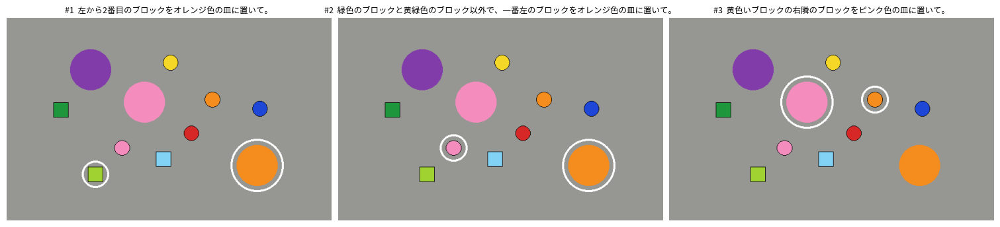

In [31]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    fm.fontManager.addfont("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"); plt.rcParams["font.family"] = "Noto Sans CJK JP"
except Exception as e:
    print("日本語フォントを設定できなかった:", e)

def preview_scene(seed, idx):
    objs, targets = get_scene(seed); t = targets[idx - 1]
    img = Image.new("RGB", (IMG_W, IMG_H), (150, 150, 146)); d = ImageDraw.Draw(img)
    for o in objs:
        u, v = world_to_pixel(o.X, o.Y, 0.0); r = o.r * _F / TOP_POS[2]; col = COLORS[o.color]
        if o.kind == "plate":   d.ellipse([u-r, v-r, u+r, v+r], fill=col)
        elif o.shape == "cube": d.rectangle([u-r, v-r, u+r, v+r], fill=col, outline=(0, 0, 0))
        else:                   d.ellipse([u-r, v-r, u+r, v+r], fill=col, outline=(0, 0, 0))
        if (o.kind == "block" and o.color == t["tb"]) or (o.kind == "plate" and o.color == t["tw"]):
            R = r + 12; d.ellipse([u-R, v-R, u+R, v+R], outline=(255, 255, 255), width=4)
    return img

# 目標の確認（白い輪が、目標のブロックと皿）
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for ax, i in zip(axes, (1, 2, 3)):
    ax.imshow(preview_scene(SCENE_CANDIDATES[0], i)); ax.axis("off")
    ax.set_title(f"#{i}  {instruction(targets[i-1], 3)}", fontsize=9)
plt.show()

## 4. 保存先

結果・グラフ・動画は、`SESSION` の名前のフォルダに保存する。同じ名前で設定（シーンや指示文など）が変わっているときは、上書きしないように止まる。

In [32]:
import shutil, datetime

def _jd(o):
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    if isinstance(o, np.ndarray): return o.tolist()
    raise TypeError(f"JSONにできない型: {type(o)}")

def atomic_write_json(path, obj):
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=1, default=_jd)
    os.replace(tmp, path)               # 途中で切れても、壊れた本ファイルは残らない

def read_json(path):
    if not os.path.exists(path):
        return None
    try:
        with open(path, encoding="utf-8") as f:
            return json.load(f)
    except Exception:
        os.remove(path)                 # 壊れたファイルは捨てて、やり直させる
        return None

def unique_path(directory, filename):
    """既存のファイルを上書きしない保存先（同名があれば _2, _3 …を付ける）"""
    base, ext = os.path.splitext(filename)
    p, k = os.path.join(directory, filename), 2
    while os.path.exists(p):
        p = os.path.join(directory, f"{base}_{k}{ext}"); k += 1
    return p

def init_session():
    """SESSION ごとに保存先を分ける。同じ SESSION で設定が変わっていたら、上書きせずに止める。"""
    global SESSION_DIR, ER_DIR, SCENE_DIR, RESULT_DIR, VIDEO_DIR, PLOT_DIR
    root = "/content/gemini_robotics_sessions"
    if USE_DRIVE:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            root = "/content/drive/MyDrive/gemini_robotics_sessions"
        except Exception as e:
            print("Driveをマウントできなかった。ローカルに保存する（ランタイムが切れると消える）:", e)
    SESSION_DIR = os.path.join(root, SESSION)
    ER_DIR, SCENE_DIR, RESULT_DIR, VIDEO_DIR, PLOT_DIR = (
        os.path.join(SESSION_DIR, d) for d in ("er", "scenes", "results", "videos", "plots"))
    for d in (SESSION_DIR, ER_DIR, SCENE_DIR, RESULT_DIR, VIDEO_DIR, PLOT_DIR):
        os.makedirs(d, exist_ok=True)

    cfg = {"geom": GEOM_VERSION, "signature": config_signature(), "model": MODEL_ID,
           "thinking": THINKING_BUDGET, "light_target": LIGHT_TARGET}
    path = os.path.join(SESSION_DIR, "config.json")
    old = read_json(path)
    if old is None:
        atomic_write_json(path, {**cfg, "created": datetime.datetime.now().isoformat(timespec="seconds")})
        print(f"新しいセッション '{SESSION}' を作った。")
    else:
        diff = {k: (old.get(k), cfg[k]) for k in cfg if old.get(k) != cfg[k]}
        if diff:
            raise RuntimeError(
                f"セッション '{SESSION}' は別の設定で作られている（上書きを防ぐため止めた）。\n"
                f"  違い（保存済み → 今回）: {diff}\n"
                f"  設定のセルの SESSION を、新しい名前に変える。")
        print(f"既存のセッション '{SESSION}' を再開する（設定は同じ）。")
    print("保存先:", SESSION_DIR)

init_session()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
新しいセッション 'run04' を作った。
保存先: /content/drive/MyDrive/gemini_robotics_sessions/run04


## 5. ロボットの制御と環境

次のセルは、関数やクラスの定義だけで、実行しても何も起きない。

- 逆運動学：手先を真下に向けたまま、目標の位置に指先を合わせる関節の角度を求める。
- 環境：MuJoCo Menagerie の Franka Panda と、床・ブロック・皿。関節は位置制御、グリッパは摩擦で掴む。
- 1回の実行：接近 → 降下 → 掴む → 持ち上げ → 運ぶ → 皿の上に降ろす → 離す → ホームに戻る。次の4段階で成否を見る。

| 段階 | 判定 |
|---|---|
| 認識 | ER の点が、正しいブロックの3cm以内／正しい皿の範囲内 |
| 把持 | 持ち上げた後、正しいブロックが手先と一緒に浮いている |
| 運搬 | 皿の上に着いた時点でも、まだ掴んでいる |
| 設置 | 最後に、正しいブロックが正しい皿の上にある |

- ER への問い合わせと集計：結果は1回ごとに保存し、1日の上限で止まっても続きから回せる。

In [33]:
class Unreachable(Exception):
    pass

def _rot_err(R, Rd, yaw_free):
    if yaw_free:                                   # ブロックは対称なので、手先の向き（ヨー）は自由にする
        return np.cross(R[:, 2], Rd[:, 2])
    return 0.5 * (np.cross(R[:, 0], Rd[:, 0]) + np.cross(R[:, 1], Rd[:, 1]) + np.cross(R[:, 2], Rd[:, 2]))

def damped_ik(fk, jac, q0, p_des, R_des, q_lo, q_hi, q_home=None, yaw_free=False,
              iters=300, damping=0.02, step=0.8, tol_p=4e-4, tol_r=1.5e-2):
    """減衰最小二乗法のIK。fk(q)->(位置, 回転行列), jac(q)->6x7（上3行=位置, 下3行=回転）"""
    q = np.array(q0, float)
    n = len(q)
    for it in range(iters):
        p, R = fk(q)
        ep = p_des - p
        er = _rot_err(R, R_des, yaw_free)
        if np.linalg.norm(ep) < tol_p and np.linalg.norm(er) < tol_r:
            return q, True, it
        J = jac(q)
        err = np.concatenate([ep, er])
        Jp = J.T @ np.linalg.inv(J @ J.T + damping**2 * np.eye(6))
        dq = Jp @ err
        if q_home is not None:                     # 余剰自由度でホーム姿勢に寄せる（関節が暴れるのを防ぐ）
            dq += (np.eye(n) - Jp @ J) @ (0.15 * (np.asarray(q_home) - q))
        m = np.max(np.abs(dq))
        if m > 0.25:
            dq *= 0.25 / m
        q = np.clip(q + step * dq, q_lo, q_hi)
    p, R = fk(q)
    ok = np.linalg.norm(p_des - p) < 2e-3 and np.linalg.norm(_rot_err(R, R_des, yaw_free)) < 3e-2
    return q, ok, iters

def solve_pose(fk, jac, q_cur, p_des, R_des, q_lo, q_hi, q_home):
    """まず向き固定で解き、だめならヨー自由で解く。(q, yaw_free) を返す。解けなければ Unreachable"""
    for yaw_free in (False, True):
        q, ok, _ = damped_ik(fk, jac, q_cur, p_des, R_des, q_lo, q_hi, q_home, yaw_free=yaw_free)
        if ok:
            return q, yaw_free
    raise Unreachable(f"IKが解けません: 目標={np.round(p_des, 3)}")

In [34]:
import re
import mujoco
import imageio.v2 as imageio

HOME_Q = np.array([0, 0, 0, -1.57079, 0, 1.57079, -0.7853])   # Franka の標準的な待機姿勢
LIGHT_SCALE = 1.0                                             # 照明の倍率（calibrate_light が決める）
TCP_OFFSET = 0.1034                                           # ハンド座標から指先中心までの距離 [m]

def _lookat_xyaxes(pos, target):
    f = np.array(target, float) - np.array(pos, float); f /= np.linalg.norm(f)
    right = np.cross(f, [0, 0, 1]); right /= np.linalg.norm(right)
    up = np.cross(right, f)
    return " ".join(f"{v:.5f}" for v in (*right, *up))

def prepare_panda_xml():
    """menagerie の panda.xml からキーフレームを除いた版を作る（物体を足すと次元が合わなくなるため）"""
    s = open(f"{PANDA_DIR}/panda.xml", encoding="utf-8").read()
    s = re.sub(r"<keyframe>.*?</keyframe>", "", s, flags=re.S)
    open(f"{PANDA_DIR}/panda_nokey.xml", "w", encoding="utf-8").write(s)

def build_scene_xml(objs):
    mats, items, nb, npl = [], [], 0, 0
    for k, o in enumerate(objs):
        r, g, b = (c / 255 for c in COLORS[o.color])
        # 光沢なし（specular=0）の材質を、物体ごとに作る
        mats.append(f'<material name="c{k}" rgba="{r:.3f} {g:.3f} {b:.3f} 1" specular="0" shininess="0" reflectance="0"/>')
        if o.kind == "block":
            if o.shape == "cube":
                geom = f'<geom type="box" size="{BLOCK_H} {BLOCK_H} {BLOCK_H}"'
            else:
                geom = f'<geom type="cylinder" size="{BLOCK_H} {BLOCK_H}"'
            items.append(f'<body name="block{nb}" pos="{o.X:.4f} {o.Y:.4f} {BLOCK_H}"><freejoint name="fj{nb}"/>'
                         f'{geom} material="c{k}" mass="0.05" friction="1.5 0.05 0.001" condim="4"/></body>')
            nb += 1
        else:   # 皿は見た目だけ（衝突なし）の薄い円盤
            items.append(f'<geom name="plate{npl}" type="cylinder" size="{PLATE_R} 0.002" '
                         f'pos="{o.X:.4f} {o.Y:.4f} 0.002" material="c{k}" contype="0" conaffinity="0"/>')
            npl += 1
    side_pos = (1.00, -0.80, 0.65)
    return f"""<mujoco model="jp_pick_place">
  <include file="panda_nokey.xml"/>
  <asset>
    <texture name="grid" type="2d" builtin="checker" rgb1="0.62 0.62 0.60" rgb2="0.56 0.56 0.54" width="300" height="300"/>
    <material name="grid" texture="grid" texrepeat="8 8" texuniform="true" specular="0" shininess="0" reflectance="0"/>
    {chr(10).join(mats)}
  </asset>
  <worldbody>
    <!-- 光の合計（ヘッドライト0.5 + 下の2灯）が、上面でおよそ1.0以下になるようにする。影は付けない -->
    <light name="top_light" pos="0.5 0 2.0" dir="0 0 -1" directional="true" ambient="0.1 0.1 0.1" diffuse="0.25 0.25 0.25" specular="0 0 0" castshadow="false"/>
    <light name="fill_light" pos="2 1 2" dir="-0.6 -0.3 -0.6" directional="true" ambient="0 0 0" diffuse="0.2 0.2 0.2" specular="0 0 0" castshadow="false"/>
    <geom name="floor" type="plane" size="2 2 0.05" material="grid"/>
    <camera name="top" pos="{TOP_POS[0]} {TOP_POS[1]} {TOP_POS[2]}" xyaxes="0 -1 0 1 0 0" fovy="{TOP_FOVY}"/>
    <camera name="side" pos="{side_pos[0]} {side_pos[1]} {side_pos[2]}" xyaxes="{_lookat_xyaxes(side_pos, (0.42, 0.0, 0.10))}" fovy="45"/>
    {chr(10).join(items)}
  </worldbody>
</mujoco>"""

def make_writer(path, fps=30):
    return imageio.get_writer(path, fps=fps, codec="libx264", quality=8, macro_block_size=16)

class PickPlaceEnv:
    """Franka Panda（MuJoCo Menagerie）の卓上 pick & place 環境。IKで関節目標を作り、位置サーボで動かす"""
    def __init__(self, objs):
        self.objs = objs
        prepare_panda_xml()
        path = os.path.join(PANDA_DIR, "scene_task.xml")
        with open(path, "w", encoding="utf-8") as f:
            f.write(build_scene_xml(objs))
        m = self.model = mujoco.MjModel.from_xml_path(path)
        self.data = mujoco.MjData(m)
        m.opt.cone = mujoco.mjtCone.mjCONE_ELLIPTIC      # 把持を安定させる設定
        m.opt.impratio = 10.0
        self.dt = m.opt.timestep
        self._head0 = (np.array(m.vis.headlight.ambient, float), np.array(m.vis.headlight.diffuse, float))
        self._light0 = (m.light_ambient.copy(), m.light_diffuse.copy())
        self.set_light_scale(LIGHT_SCALE)
        assert m.nu >= 8, f"アクチュエータ数が想定（8）と違います: {m.nu}"

        try:
            self.arm_j = [m.joint(f"joint{i}").id for i in range(1, 8)]
        except KeyError:
            self.arm_j = list(range(7))
        self.arm_qadr = np.array([m.jnt_qposadr[j] for j in self.arm_j])
        self.arm_dadr = np.array([m.jnt_dofadr[j] for j in self.arm_j])
        self.q_lo = m.jnt_range[self.arm_j, 0].copy(); self.q_hi = m.jnt_range[self.arm_j, 1].copy()
        self.hand = m.body("hand").id
        try:
            self.finger_qadr = [m.jnt_qposadr[m.joint(n).id] for n in ("finger_joint1", "finger_joint2")]
        except KeyError:
            self.finger_qadr = [m.jnt_qposadr[j] for j in (7, 8)]
        self.grip_open = float(m.actuator_ctrlrange[7, 1]); self.grip_close = float(m.actuator_ctrlrange[7, 0])

        self.block_bid, nb = {}, 0
        for o in objs:
            if o.kind == "block":
                self.block_bid[o.color] = m.body(f"block{nb}").id; nb += 1
        self.plates = {o.color: o for o in objs if o.kind == "plate"}

        self._ikd = mujoco.MjData(m)         # IK 計算用の作業データ（シミュレーションには触れない）
        self._r = None; self.writer = None; self.phase = ""; self.caption = ""; self.marks = []
        self.result = None; self.label = "ER"; self._tick = 0
        self.cap_every = max(1, round(1.0 / (30.0 * self.dt)))   # 約30fpsで記録
        self.yaw_free_used = False
        self.R_down = self._fk(HOME_Q)[1]                          # 待機姿勢の手先の向き = 真下
        if self.R_down[2, 2] > -0.9:
            print("警告: 待機姿勢で手先が真下を向いていません。R_down =", self.R_down.round(2))
        self.reset()

    # ----- 運動学 -----
    def _fk(self, q):
        d = self._ikd; d.qpos[self.arm_qadr] = q
        mujoco.mj_kinematics(self.model, d)
        R = d.xmat[self.hand].reshape(3, 3).copy()
        return d.xpos[self.hand] + R @ np.array([0, 0, TCP_OFFSET]), R

    def _jac(self, q):
        d, m = self._ikd, self.model
        d.qpos[self.arm_qadr] = q
        mujoco.mj_forward(m, d)
        R = d.xmat[self.hand].reshape(3, 3)
        p = d.xpos[self.hand] + R @ np.array([0, 0, TCP_OFFSET])
        jp = np.zeros((3, m.nv)); jr = np.zeros((3, m.nv))
        mujoco.mj_jac(m, d, jp, jr, p, self.hand)
        return np.vstack([jp[:, self.arm_dadr], jr[:, self.arm_dadr]])

    def tcp(self):
        d = self.data
        R = d.xmat[self.hand].reshape(3, 3)
        return d.xpos[self.hand] + R @ np.array([0, 0, TCP_OFFSET])

    # ----- シミュレーション -----
    def reset(self):
        m, d = self.model, self.data
        mujoco.mj_resetData(m, d)
        d.qpos[self.arm_qadr] = HOME_Q
        for a in self.finger_qadr:
            d.qpos[a] = 0.04
        d.ctrl[:7] = HOME_Q; d.ctrl[7] = self.grip_open
        mujoco.mj_forward(m, d)
        w, self.writer = self.writer, None       # 準備中は記録しない
        self.step(int(0.6 / self.dt))
        self.writer = w
        self.init_pos = {c: self.data.xpos[b].copy() for c, b in self.block_bid.items()}
        self.yaw_free_used = False

    def step(self, n):
        m, d = self.model, self.data
        for _ in range(n):
            mujoco.mj_step(m, d)
            self._tick += 1
            if self.writer is not None and self._tick % self.cap_every == 0:
                self._capture()

    def settle(self, T):
        self.step(int(T / self.dt))

    def move_joint(self, q1, T=None):
        q0 = self.data.qpos[self.arm_qadr].copy()
        if T is None:
            T = float(np.clip(np.max(np.abs(q1 - q0)) / 0.9, 0.6, 2.5))
        n = max(1, int(T / self.dt))
        for i in range(1, n + 1):
            s = i / n; s = s * s * (3 - 2 * s)             # なめらかな加減速
            self.data.ctrl[:7] = q0 + (q1 - q0) * s
            self.step(1)
        self.data.ctrl[:7] = q1
        self.step(int(0.15 / self.dt))

    def goto(self, p, T=None, phase=None):
        if phase:
            self.phase = phase
        q_cur = self.data.qpos[self.arm_qadr].copy()
        q, yf = solve_pose(self._fk, self._jac, q_cur, np.asarray(p, float), self.R_down,
                           self.q_lo, self.q_hi, HOME_Q)
        self.yaw_free_used |= yf
        self.move_joint(q, T)

    def goto_home(self, phase=None):
        if phase:
            self.phase = phase
        self.move_joint(HOME_Q.copy())

    def grip(self, open_, T, phase=None):
        if phase:
            self.phase = phase
        self.data.ctrl[7] = self.grip_open if open_ else self.grip_close
        self.step(int(T / self.dt))

    # ----- 状態の読み取り -----
    def obj_by(self, kind, color):
        return next(o for o in self.objs if o.kind == kind and o.color == color)

    def block_pos(self, color):
        return self.data.xpos[self.block_bid[color]].copy()

    def held_blocks(self):
        tcp = self.tcp(); out = []
        for c in self.block_bid:
            pos = self.block_pos(c)
            if pos[2] > 0.08 and np.linalg.norm(pos - tcp) < 0.07:
                out.append((np.linalg.norm(pos - tcp), c))
        return [c for _, c in sorted(out)]

    def plate_containing(self, color):
        pos = self.block_pos(color)
        if pos[2] > 0.045:
            return None
        for pc, o in self.plates.items():
            if math.hypot(pos[0] - o.X, pos[1] - o.Y) < PLATE_R * 0.95:
                return pc
        return None

    def collateral(self, tb):
        return sum(1 for c in self.block_bid if c != tb and np.linalg.norm(self.block_pos(c) - self.init_pos[c]) > 0.02)

    def set_light_scale(self, s):
        """照明全体（ヘッドライト＋2灯）の強さを s 倍にする"""
        m = self.model
        m.vis.headlight.ambient[:] = self._head0[0] * s
        m.vis.headlight.diffuse[:] = self._head0[1] * s
        m.light_ambient[:] = self._light0[0] * s
        m.light_diffuse[:] = self._light0[1] * s

    # ----- 描画・記録 -----
    def render(self, cam):
        if self._r is None:
            self._r = mujoco.Renderer(self.model, IMG_H, IMG_W)
        self._r.update_scene(self.data, camera=cam)
        return self._r.render().copy()

    def render_clear(self, cam="top"):
        """アームを画角の外へ回して撮る（ER に見せる画像用。物理状態は変えない）"""
        d = self.data; qa = self.arm_qadr[0]
        saved = d.qpos[qa]
        d.qpos[qa] = saved + np.pi / 2     # 土台の関節を90度回し、アームを横へ逃がす
        mujoco.mj_forward(self.model, d)
        img = self.render(cam)
        d.qpos[qa] = saved
        mujoco.mj_forward(self.model, d)
        return img

    def begin_recording(self, writer, caption, marks, label="ER"):
        self.writer, self.caption, self.marks, self.result, self.label = writer, caption, marks, None, label

    def _capture(self):
        top, side = self.render("top"), self.render("side")
        self.writer.append_data(compose_frame(top, side, self.caption, self.phase, self.marks, self.result, self.label))

    def end_recording(self, result_text):
        self.result = result_text
        for _ in range(45):    # 結果を1.5秒表示
            self._capture()
        self.writer = None

    def close(self):
        if self._r is not None:
            self._r.close(); self._r = None

In [35]:
from PIL import Image, ImageDraw, ImageFont
import pandas as pd

# ---------- 動作の高さ [m]（TCP＝指先の中心）----------
HOVER_Z, GRASP_Z, CARRY_Z, RELEASE_Z = 0.16, 0.018, 0.22, 0.07

CLS_JA = {"success": "成功", "grasp_failed": "掴めなかった（認識は合っていた）",
          "missed_block": "ブロックを外した（認識の誤り）", "wrong_block": "別のブロックを掴んだ",
          "dropped": "運搬中に落とした", "wrong_plate": "別の皿に置いた",
          "missed_plate": "皿に載らなかった", "unreachable": "届かない", "parse_error": "出力を解釈できない"}

def classify_episode(res):
    st = res["status"]
    if st in ("parse_error", "unreachable"):
        return st
    if res["success"]:
        return "success"
    if res["lifted"] is None:
        return "grasp_failed" if res["point_ok_block"] else "missed_block"
    if res["lifted"] != res["tb"]:
        return "wrong_block"
    if not res["carry_ok"]:
        return "dropped"
    return "wrong_plate" if res["final_plate"] not in (None, res["tw"]) else "missed_plate"

# ---------- 動画フレームの合成（左=ERに見せた真上画像＋認識結果、右=斜めから見た画像）----------
FONT_PATH = "/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc"
HEADER = 80
def _font(size):
    try:
        return ImageFont.truetype(FONT_PATH, size)
    except Exception:
        return ImageFont.load_default()
FONT_L, FONT_M, FONT_X, FONT_S = _font(26), _font(21), _font(17), _font(20)

def compose_frame(top, side, caption, phase, marks, result=None, label="ER"):
    W2, H2 = IMG_W * 2, IMG_H + HEADER
    canvas = Image.new("RGB", (W2, H2), (24, 24, 28))
    t = Image.fromarray(top); dt = ImageDraw.Draw(t)
    for (u, v, kind) in marks:
        if kind == "block":
            dt.line([u-14, v-14, u+14, v+14], fill=(255, 40, 40), width=4)
            dt.line([u-14, v+14, u+14, v-14], fill=(255, 40, 40), width=4)
            dt.text((u+16, v-28), f"{label}: ブロック", font=FONT_S, fill=(255, 255, 255), stroke_width=2, stroke_fill=(0, 0, 0))
        else:
            dt.ellipse([u-16, v-16, u+16, v+16], outline=(0, 90, 255), width=4)
            dt.text((u+18, v-8), f"{label}: 皿", font=FONT_S, fill=(255, 255, 255), stroke_width=2, stroke_fill=(0, 0, 0))
    canvas.paste(t, (0, HEADER)); canvas.paste(Image.fromarray(side), (IMG_W, HEADER))
    d = ImageDraw.Draw(canvas)
    text = f"指示: {caption}"
    for f in (FONT_L, FONT_M, FONT_X):                 # 長い指示は、文字を小さくして1行に収める
        if d.textlength(text, font=f) <= W2 - 32:
            break
    d.text((16, 8), text, font=f, fill=(255, 255, 255))
    d.text((16, 46), f"動作: {phase}", font=FONT_S, fill=(170, 210, 255))
    if result:
        d.text((W2 - 520, 46), f"結果: {result}", font=FONT_S, fill=(255, 220, 120))
    return np.asarray(canvas)

# ---------- 1エピソード（1つの目標を、1つの指示で）の実行 ----------
def run_episode(env, tgt, pred, instruction_text, writer=None, caption="", keep_images=False, label="ER"):
    """pred = {"block": [y,x], "plate": [y,x]}（0-1000正規化）。None なら出力崩れ扱い"""
    tb, tw = tgt["tb"], tgt["tw"]
    env.reset()
    res = {"idx": tgt["idx"], "cat": tgt["cat"], "tmpl": tgt["tmpl"], "tb": tb, "tw": tw, "instruction": instruction_text,
           "point_ok_block": False, "point_ok_plate": False, "err_block_m": np.nan, "err_plate_m": np.nan,
           "lifted": None, "grasp_ok": False, "carry_ok": False, "final_plate": None,
           "place_ok": False, "collateral": 0, "success": False, "status": "done", "error": ""}
    if pred is None:
        res["status"] = "parse_error"; res["cls"] = "parse_error"
        return res

    (yb, xb), (yp, xp) = pred["block"], pred["plate"]
    bX, bY = pixel_to_world(xb / 1000 * IMG_W, yb / 1000 * IMG_H, BLOCK_H)
    pX, pY = pixel_to_world(xp / 1000 * IMG_W, yp / 1000 * IMG_H, 0.0)
    tgt_b, tgt_p = env.obj_by("block", tb), env.obj_by("plate", tw)
    res["err_block_m"] = math.hypot(bX - tgt_b.X, bY - tgt_b.Y)
    res["err_plate_m"] = math.hypot(pX - tgt_p.X, pY - tgt_p.Y)
    res["point_ok_block"] = bool(res["err_block_m"] < 0.03)       # 点がブロックの上（3cm以内）
    res["point_ok_plate"] = bool(res["err_plate_m"] < PLATE_R)    # 点が皿の範囲内
    res["pred_block"], res["pred_plate"] = pred["block"], pred["plate"]
    if keep_images:
        res["img_before"] = env.render_clear("top")
    if writer is not None:
        marks = [(xb / 1000 * IMG_W, yb / 1000 * IMG_H, "block"), (xp / 1000 * IMG_W, yp / 1000 * IMG_H, "plate")]
        env.begin_recording(writer, caption or instruction_text, marks, label)

    try:
        env.grip(True, 0.2, phase="準備")
        env.goto((bX, bY, HOVER_Z), phase="ブロックへ接近")
        env.goto((bX, bY, GRASP_Z), phase="降下")
        env.grip(False, 0.8, phase="把持")
        env.goto((bX, bY, CARRY_Z), T=1.5, phase="持ち上げ")
        held = env.held_blocks()                                    # 持ち上がっているブロック
        res["lifted"] = held[0] if held else None
        res["grasp_ok"] = (res["lifted"] == tb)
        env.goto((pX, pY, CARRY_Z), phase="運搬")
        held2 = env.held_blocks()
        res["carry_ok"] = bool(held2) and held2[0] == tb
        env.goto((pX, pY, RELEASE_Z), phase="皿の上へ降ろす")
        env.grip(True, 0.6, phase="解放")
        env.goto((pX, pY, CARRY_Z), phase="退避")
        env.goto_home(phase="ホームへ戻る")
        env.settle(0.8)
    except Unreachable as e:
        res["status"] = "unreachable"; res["error"] = str(e)

    res["final_plate"] = env.plate_containing(tb)
    res["place_ok"] = (res["final_plate"] == tw)
    res["collateral"] = env.collateral(tb)
    res["success"] = bool(res["status"] == "done" and res["place_ok"])
    res["cls"] = classify_episode(res)
    if keep_images:
        res["img_after"] = env.render_clear("top")
    if writer is not None:
        env.end_recording("成功" if res["success"] else f"失敗: {CLS_JA[res['cls']]}")
    return res

def run_targets(env, targets, preds, instructions, only=None, writer=None, label="ER", kind_label=""):
    """1シーンの目標を、同じ初期配置から1つずつ実行する。instructions[i] は idx=i+1 の指示文"""
    rows = []
    for i, t in enumerate(targets, 1):
        if only is not None and i not in only:
            continue
        cap = f"{kind_label}{instructions[i-1]}"
        rows.append(run_episode(env, t, preds.get(i), instructions[i-1], writer=writer, caption=cap, label=label))
    return rows


# ---------- 動画 ----------
FONT_T, FONT_ST = _font(54), _font(26)

def title_card(title, sub):
    img = Image.new("RGB", (IMG_W * 2, IMG_H + HEADER), (24, 24, 28)); d = ImageDraw.Draw(img)
    for text, f, y in ((title, FONT_T, 170), (sub, FONT_ST, 270)):
        d.text(((IMG_W * 2 - d.textlength(text, font=f)) / 2, y), text, font=f, fill=(255, 255, 255))
    return np.asarray(img)

class Clip:
    """動画の書き出し。まずローカルに書いて、閉じるときに保存先へコピーする（同名のファイルは上書きしない）"""
    FPS = 30
    def __init__(self, dest_dir, name):
        os.makedirs("/content/_tmp_videos", exist_ok=True)
        self.local = f"/content/_tmp_videos/tmp_{int(time.time() * 1000)}.mp4"
        self.dest_dir, self.name, self.n = dest_dir, name, 0
        self.w = make_writer(self.local, fps=self.FPS)
    def append_data(self, frame):
        self.w.append_data(frame); self.n += 1
    def close(self):
        self.w.close()
        dest = unique_path(self.dest_dir, self.name)
        shutil.copy(self.local, dest); os.remove(self.local)
        return dest
    @property
    def seconds(self):
        return self.n / self.FPS

In [36]:
LIGHT_READY = False      # 照明の調整が済んだか（調整前の画像を ER に見せないための確認）

def GEN_CONFIG():
    if THINKING_BUDGET == 0:
        return None      # 元のノートブックと同じ設定（思考なし）
    return types.GenerateContentConfig(
        temperature=1.0, thinking_config=types.ThinkingConfig(thinking_budget=THINKING_BUDGET))

def er_path(seed, kind, rep=0):
    return os.path.join(ER_DIR, f"er_s{seed}_K{kind}_r{rep}.json")

def load_er(seed, kind, rep=0):
    d = read_json(er_path(seed, kind, rep))
    return None if d is None else d["raw"]

_IMG = {}
def scene_image(seed):
    """ER に見せる真上の画像（アームは写さない）。3種類の指示で同じ画像を使う"""
    key = (seed, round(LIGHT_SCALE, 4))
    if key not in _IMG:
        objs, _ = get_scene(seed)
        env = PickPlaceEnv(objs)
        arr = env.render_clear("top"); env.close()
        _IMG[key] = Image.fromarray(arr)
        png = os.path.join(SCENE_DIR, f"scene_{seed}_light{LIGHT_SCALE:.2f}.png")
        if not os.path.exists(png):
            _IMG[key].save(png)
    return _IMG[key]

def call_er(seed, kind, rep=0):
    """1つのシーンについて、1種類の指示（10個）を ER に聞く。保存済みなら API は呼ばない"""
    objs, targets = get_scene(seed)
    raw = load_er(seed, kind, rep)
    if raw is None:
        if not LIGHT_READY:
            raise ValueError("先に照明の調整（prepare_light）を実行する")
        img = scene_image(seed)
        try:
            raw = call_gemini_robotics_er(img, build_prompt(targets, kind), config=GEN_CONFIG())
        except RuntimeError:
            raise                       # 1日の上限。呼び出し側で止める
        except AttributeError:
            raw = ""                    # 応答が空
        except Exception as e:
            print(f"  skip seed={seed} kind={kind}: {type(e).__name__}: {str(e)[:120]}")
            return None
        atomic_write_json(er_path(seed, kind, rep),
                          {"seed": seed, "kind": kind, "rep": rep,
                           "instructions": [instruction(t, kind) for t in targets],
                           "raw": raw, "model": MODEL_ID, "thinking_budget": THINKING_BUDGET,
                           "light_scale": LIGHT_SCALE})
    return raw

def run_er(seeds, kinds=KIND_KEYS, reps=1):
    """まだ聞いていないものだけ ER に聞く。1日の上限で止まっても、再実行すると続きから回る"""
    todo = [(s, k, r) for s in seeds for k in kinds for r in range(reps) if load_er(s, k, r) is None]
    total = len(seeds) * len(kinds) * reps
    print(f"済み {total - len(todo)}/{total}、これから {len(todo)}回（約 {len(todo) * 13 / 60:.1f} 分）")
    for s, k, r in todo:
        try:
            call_er(s, k, r)
            print(f"  seed={s} {KIND_DESC[k]} 完了")
        except RuntimeError as e:
            print("\n中断:", e)
            print("ここまでの結果は保存してある。上限が戻ったら、同じセルをもう一度実行する。")
            break
    done = sum(load_er(s, k, r) is not None for s in seeds for k in kinds for r in range(reps))
    print(f"保存済み {done}/{total}")

def er_preds(seed, kind, rep=0):
    raw = load_er(seed, kind, rep)
    return None if raw is None else parse_batch(raw, sum(COUNTS.values()))

In [45]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
try:
    fm.fontManager.addfont("/usr/share/fonts/opentype/noto/NotoSansCJK-Regular.ttc")
    plt.rcParams["font.family"] = "Noto Sans CJK JP"
except Exception as e:
    print("日本語フォントを設定できなかった（図の日本語が文字化けするかもしれない）:", e)

# ===================== 照明の調整 =====================
def measure_gain(env):
    """画像の中の物体の上面が、本来の色の何倍の明るさで写っているか（白飛びしていない成分の中央値）"""
    img = env.render_clear("top").astype(float)
    gains = []
    for o in env.objs:
        z = 2 * BLOCK_H if o.kind == "block" else 0.004
        u, v = (int(round(t)) for t in world_to_pixel(o.X, o.Y, z))
        patch = img[v-3:v+4, u-3:u+4].reshape(-1, 3).mean(0)
        want = np.array(COLORS[o.color], float)
        gains += [ob / wa for ob, wa in zip(patch, want) if wa >= 40 and ob < 250]
    return float(np.median(gains)) if gains else float("nan")

def calibrate_light(env, target=0.95, iters=6, tol=0.03):
    """明るさの比が target になるまで、照明の強さを調整する。(倍率, 履歴) を返す"""
    s = 1.0
    env.set_light_scale(s)
    hist = []
    for k in range(iters):
        g = measure_gain(env); hist.append((round(s, 4), round(g, 3)))
        if not np.isfinite(g) or abs(g - target) < tol:
            break
        s = float(np.clip(s * target / g, 0.2, 2.0))
        env.set_light_scale(s)
        if k == 0:
            g2 = measure_gain(env)
            if np.isfinite(g2) and abs(g2 - g) < 1e-3:
                raise RuntimeError("照明の倍率が画像に反映されていない（set_light_scale が効いていない）")
    else:
        hist.append((round(s, 4), round(measure_gain(env), 3)))
    return s, hist

def prepare_light(force=False):
    """セッションに照明の倍率が保存されていればそれを使い、なければ調整する"""
    global LIGHT_SCALE, LIGHT_READY
    path = os.path.join(SESSION_DIR, "light.json")
    d = None if force else read_json(path)
    if d is None:
        objs, _ = get_scene(SCENE_CANDIDATES[0])
        LIGHT_SCALE = 1.0
        env = PickPlaceEnv(objs)
        s, hist = calibrate_light(env, LIGHT_TARGET); env.close()
        LIGHT_SCALE = s
        d = {"scale": s, "history": hist, "target": LIGHT_TARGET}
        atomic_write_json(path, d)
    else:
        LIGHT_SCALE = d["scale"]
    LIGHT_READY = True
    print(f"照明の倍率 = {LIGHT_SCALE:.3f}（[倍率, 明るさの比] の履歴: {d['history']}）")
    return d

# ===================== 物理シミュレーションの実行（結果は保存）=====================
class LazyEnv:
    """必要になるまで環境を作らない。結果が保存済みなら、シミュレータを起動しない"""
    def __init__(self, objs):
        self.objs, self.env = objs, None
    def get(self):
        if self.env is None:
            self.env = PickPlaceEnv(self.objs)
        return self.env
    def close(self):
        if self.env is not None:
            self.env.close(); self.env = None

def oracle_rows(seed, lazy):
    """正解の座標で実行した結果（制御と物理だけの成功率）"""
    path = os.path.join(RESULT_DIR, f"oracle_s{seed}.json")
    d = read_json(path)
    if d is None:
        objs, targets = get_scene(seed)
        rows = run_targets(lazy.get(), targets, oracle_preds(objs, targets), [instruction(t, 1) for t in targets])
        for r in rows:
            r.update(seed=seed, kind=0, rep=0)
        d = {"rows": rows}; atomic_write_json(path, d)
    return d["rows"]

def kind_rows(seed, kind, rep, lazy):
    path = os.path.join(RESULT_DIR, f"s{seed}_K{kind}_r{rep}.json")
    d = read_json(path)
    if d is None:
        preds = er_preds(seed, kind, rep)
        if preds is None:
            return None
        _, targets = get_scene(seed)
        rows = run_targets(lazy.get(), targets, preds, [instruction(t, kind) for t in targets])
        for r in rows:
            r.update(seed=seed, kind=kind, rep=rep)
        d = {"rows": rows}; atomic_write_json(path, d)
    return d["rows"]

def select_scenes(n, candidates=None):
    """正解座標で全目標を実行し、成功率が ORACLE_MIN 以上のシーンを n 個選ぶ。結果はセッションに保存する"""
    path = os.path.join(SESSION_DIR, "scenes.json")
    st = read_json(path) or {"accepted": [], "tried": {}}
    for seed in (candidates or SCENE_CANDIDATES):
        if len(st["accepted"]) >= n:
            break
        if str(seed) in st["tried"]:
            continue
        lazy = LazyEnv(get_scene(seed)[0])
        rows = oracle_rows(seed, lazy); lazy.close()
        rate = float(np.mean([r["success"] for r in rows]))
        st["tried"][str(seed)] = rate
        if rate >= ORACLE_MIN:
            st["accepted"].append(seed)
        print(f"  seed={seed}: 正解座標での成功率 {rate:.0%} → {'採用' if rate >= ORACLE_MIN else '不採用'}")
        atomic_write_json(path, st)
    if len(st["accepted"]) < n:
        print(f"採用できたシーンが {len(st['accepted'])} 個だった（候補を増やすか、ORACLE_MIN を見直す）")
    return st["accepted"][:n]

def evaluate(seeds, kinds=KIND_KEYS, reps=1):
    """ER の結果（指示の種類ごと）と、正解座標の結果を返す。実行済みのものは保存から読む"""
    rows, orows = [], []
    for seed in seeds:
        lazy = LazyEnv(get_scene(seed)[0])
        orows += oracle_rows(seed, lazy)
        for kind in kinds:
            for rep in range(reps):
                r = kind_rows(seed, kind, rep, lazy)
                if r is None:
                    print(f"  未取得: seed={seed} {KIND_DESC[kind]} rep={rep}")
                else:
                    rows += r
        lazy.close()
    df, df_or = pd.DataFrame(rows), pd.DataFrame(orows)
    for d in (df, df_or):
        if len(d):
            d["point_ok"] = d["point_ok_block"] & d["point_ok_plate"]
    return df, df_or

# ===================== 集計 =====================
def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n; den = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / den
    h = z * ((p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5) / den
    return (c - h, c + h)

def mcnemar_exact(b, c):
    """片方だけ成功した件数 b, c から、両側の正確検定のp値を求める"""
    n = b + c
    if n == 0:
        return 1.0
    return min(1.0, 2 * sum(math.comb(n, i) for i in range(min(b, c) + 1)) / 2**n)

def summary_table(df, df_or=None):
    rows = []
    for K in KIND_KEYS:
        g = df[df.kind == K]
        if len(g) == 0:
            continue
        k = int(g.success.sum()); lo, hi = wilson(k, len(g))
        rows.append({"指示の種類": KIND_DESC[K], "件数": len(g), "認識OK": g.point_ok.mean(), "把持OK": g.grasp_ok.mean(),
                     "運搬OK": g.carry_ok.mean(), "成功": g.success.mean(), "95%区間": f"{lo:.2f}-{hi:.2f}"})
    if df_or is not None and len(df_or):
        g = df_or
        rows.append({"指示の種類": "（参考）正解座標", "件数": len(g), "認識OK": g.point_ok.mean(), "把持OK": g.grasp_ok.mean(),
                     "運搬OK": g.carry_ok.mean(), "成功": g.success.mean(), "95%区間": "-"})
    return pd.DataFrame(rows).set_index("指示の種類")

def paired_table(df):
    """同じ目標（シーン・目標の番号・繰り返し）どうしを対応させて、指示の種類を比べる"""
    d = df.assign(v=df["success"].astype(int))
    p = d.pivot_table(index=["seed", "rep", "idx"], columns="kind", values="v", aggfunc="first")
    rows = []
    for a, b in ((1, 2), (1, 3), (2, 3)):
        if a not in p or b not in p:
            continue
        g = p[[a, b]].dropna().astype(bool)
        ao = int((g[a] & ~g[b]).sum()); bo = int((~g[a] & g[b]).sum())
        rows.append({"比較": f"{KIND_DESC[a]} と {KIND_DESC[b]}", "目標の数": len(g),
                     "成功率(前者)": g[a].mean(), "成功率(後者)": g[b].mean(),
                     "前者だけ成功": ao, "後者だけ成功": bo, "p値(McNemar)": mcnemar_exact(ao, bo)})
    return pd.DataFrame(rows).set_index("比較")

KIND_COLORS = {1: "#4C78A8", 2: "#F58518", 3: "#E45756"}
def _label(K): return KIND_DESC[K].replace("の指示", "の\n指示")

def _save(fig, name):
    path = unique_path(PLOT_DIR, name)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    return path

def plot_kinds(df, df_or=None):
    fig, ax = plt.subplots(figsize=(8.5, 5))
    kinds = [K for K in KIND_KEYS if (df.kind == K).any()]
    for i, K in enumerate(kinds):
        g = df[df.kind == K]; k = int(g.success.sum()); n = len(g); r = k / n; lo, hi = wilson(k, n)
        ax.bar(i, r, color=KIND_COLORS[K], yerr=[[r - lo], [hi - r]], capsize=7, width=0.6)
        ax.text(i, 0.03, f"{k}/{n}\n{r:.0%}", ha="center", va="bottom", fontsize=12, fontweight="bold", color="white")
    for seed in sorted(df.seed.unique()):                      # シーンごとの値（同じ画像での違い）
        ys = [df[(df.seed == seed) & (df.kind == K)].success.mean() for K in kinds]
        ax.plot(range(len(kinds)), ys, "o--", color="gray", alpha=0.45, lw=1)
    if df_or is not None and len(df_or):
        ro = df_or.success.mean()
        ax.axhline(ro, ls=":", color="k"); ax.text(-0.45, ro + 0.012, f"正解座標での成功率 {ro:.0%}", ha="left", fontsize=9)
    ax.set_xticks(range(len(kinds))); ax.set_xticklabels([_label(K) for K in kinds])
    ax.set_ylim(0, 1.15); ax.set_ylabel("成功率（正しいブロックを正しい皿へ）")
    ax.set_title("指示の種類ごとの成功率（棒の線は95%区間、灰色の点線はシーンごと）")
    return fig

def plot_failures(df):
    order = ["success", "wrong_block", "missed_block", "grasp_failed", "dropped", "wrong_plate", "missed_plate", "unreachable", "parse_error"]
    cmap = {"success": "#54A24B", "wrong_block": "#E45756", "missed_block": "#F58518", "grasp_failed": "#B279A2",
            "dropped": "#9D755D", "wrong_plate": "#EECA3B", "missed_plate": "#BAB0AC", "unreachable": "#79706E", "parse_error": "#000000"}
    kinds = [K for K in KIND_KEYS if (df.kind == K).any()]
    fig, ax = plt.subplots(figsize=(8.5, 5)); bottom = np.zeros(len(kinds))
    for c in order:
        vals = np.array([(df[df.kind == K].cls == c).mean() for K in kinds])
        if vals.sum() == 0:
            continue
        ax.bar(range(len(kinds)), vals, bottom=bottom, color=cmap[c], label=CLS_JA[c], width=0.6)
        for i, v in enumerate(vals):
            if v >= 0.06:
                ax.text(i, bottom[i] + v / 2, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9)
        bottom += vals
    ax.set_xticks(range(len(kinds))); ax.set_xticklabels([_label(K) for K in kinds])
    ax.set_ylim(0, 1); ax.set_ylabel("割合"); ax.set_title("結果の内訳")
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9)
    return fig

def plot_breakdown(df):
    """左：日常会話の指示を言い方の型ごとに／右：複雑な指示を種類ごとに（どちらも、同じ目標を3種類の指示で比べる）"""
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [5, 4]})
    for ax, col, keys, desc, title in ((axes[0], "tmpl", TEMPLATE_KEYS, TEMPLATE_DESC, "日常会話の指示の型ごと"),
                                       (axes[1], "cat", list(CAT_DESC), CAT_DESC, "複雑な指示の種類ごと")):
        w = 0.26
        for j, K in enumerate(KIND_KEYS):
            for i, key in enumerate(keys):
                g = df[(df.kind == K) & (df[col] == key)]
                if len(g) == 0:
                    continue
                r = g.success.mean()
                ax.bar(i + (j - 1) * w, r, w, color=KIND_COLORS[K], label=KIND_DESC[K] if i == 0 else None)
                ax.text(i + (j - 1) * w, r + 0.02, f"{int(g.success.sum())}/{len(g)}", ha="center", fontsize=7.5)
        ax.set_xticks(range(len(keys))); ax.set_xticklabels([desc[k].replace("（", "\n（").replace("＋", "\n＋") for k in keys], fontsize=8.5)
        ax.set_ylim(0, 1.3); ax.set_title(title)
    axes[0].set_ylabel("成功率"); axes[0].legend(loc="upper center", ncol=3, fontsize=9)
    fig.tight_layout()
    return fig

def report(df, df_or):
    """集計表とグラフを表示し、セッションの保存先に保存する（既存のファイルは上書きしない）"""
    t1, t2 = summary_table(df, df_or), paired_table(df)
    display(t1.style.format({c: "{:.0%}" for c in ["認識OK", "把持OK", "運搬OK", "成功"]}))
    display(t2.style.format({"成功率(前者)": "{:.0%}", "成功率(後者)": "{:.0%}", "p値(McNemar)": "{:.3f}"}))
    paths = []
    for fig, name in ((plot_kinds(df, df_or), "01_success_by_kind.png"), (plot_failures(df), "02_failure_breakdown.png"),
                      (plot_breakdown(df), "03_breakdown.png")):
        paths.append(_save(fig, name)); plt.show()
    csv = unique_path(RESULT_DIR, "results_all.csv")
    pd.concat([df, df_or]).drop(columns=[c for c in ("pred_block", "pred_plate") if c in df.columns]).to_csv(csv, index=False, encoding="utf-8-sig")
    t1.to_csv(unique_path(RESULT_DIR, "summary_by_kind.csv"), encoding="utf-8-sig")
    t2.to_csv(unique_path(RESULT_DIR, "paired_tests.csv"), encoding="utf-8-sig")
    print("保存:", *paths, csv, sep="\n  ")

# ===================== 動画（指示の種類ごとに1本）=====================
VIDEO_NAMES = {
    1: "video1_normal.mp4",
    2: "video2_conversation.mp4",
    3: "video3_complex.mp4",
}

def select_video_cases(df, kind, k=4):
    """
    指示の種類ごとに動画にする目標を選ぶ。
    失敗例を最大半数程度選び、残りを成功例で補う。
    特定のシーンに限定せず、全シーンから選ぶ。
    """
    g = df[(df.kind == kind) & (df.rep == 0)].copy()

    if g.empty:
        return []

    failures = (
        g[~g["success"]]
        .sort_values(["seed", "idx"])
    )
    successes = (
        g[g["success"]]
        .sort_values(["seed", "idx"])
    )

    # まず失敗例を選ぶ（k=4なら最大2件）
    n_fail = min(max(1, k // 2), len(failures))
    selected = failures.head(n_fail)

    # 成功例を追加
    remaining = k - len(selected)
    selected = pd.concat(
        [selected, successes.head(remaining)],
        ignore_index=True
    )

    # 成功例が足りない場合は、残りの失敗例で補う
    if len(selected) < k:
        used = set(zip(selected["seed"], selected["idx"]))
        rest = failures[
            ~failures.apply(
                lambda r: (r["seed"], r["idx"]) in used,
                axis=1
            )
        ]
        selected = pd.concat(
            [selected, rest.head(k - len(selected))],
            ignore_index=True
        )

    return selected[["seed", "idx", "success", "cls"]].to_dict("records")


def make_videos_by_kind(df, k=4, rep=0):
    """
    指示の種類ごとに、その種類の成功例・失敗例を含む動画を作る。
    シーンが変わる場合は、そのシーンの環境を作り直す。
    """
    out = []

    for kind in KIND_KEYS:
        cases = select_video_cases(df, kind, k=k)

        if not cases:
            print(f"{KIND_DESC[kind]}：動画にできるデータがない")
            continue

        clip = Clip(VIDEO_DIR, VIDEO_NAMES[kind])
        card = title_card(
            KIND_DESC[kind],
            f"成功例・失敗例を含む {len(cases)} 件の実行"
        )

        for _ in range(2 * Clip.FPS):
            clip.append_data(card)

        env = None
        current_seed = None
        results = []

        try:
            for case in cases:
                seed = int(case["seed"])
                idx = int(case["idx"])

                # シーンが変わったら環境を切り替える
                if seed != current_seed:
                    if env is not None:
                        env.close()

                    objs, targets = get_scene(seed)
                    env = PickPlaceEnv(objs)
                    current_seed = seed
                    preds = er_preds(seed, kind, rep)

                if preds is None:
                    print(f"予測結果がないためスキップ: seed={seed}, kind={kind}")
                    continue

                tgt = targets[idx - 1]
                ins = instruction(tgt, kind)

                r = run_episode(
                    env,
                    tgt,
                    preds.get(idx),
                    ins,
                    writer=clip,
                    caption=f"【{KIND_DESC[kind]}】{ins}"
                )

                results.append({
                    "seed": seed,
                    "idx": idx,
                    "instruction": ins,
                    "cls": r["cls"],
                    "success": r["success"],
                })

        finally:
            if env is not None:
                env.close()

        secs = clip.seconds
        path = clip.close()

        out.append({
            "kind": kind,
            "path": path,
            "seconds": secs,
            "results": results,
        })

    return out

## 6. 環境と照明の確認

mujoco 3.17.0
nq, nv, nu = 65 57 8 / 物体の数: 11
待機姿勢の指先の位置: [ 0.555 -0.     0.514]  手先のz軸: [ 0. -0. -1.]
調整前の明るさの比（写った色 / 本来の色）: 1.42


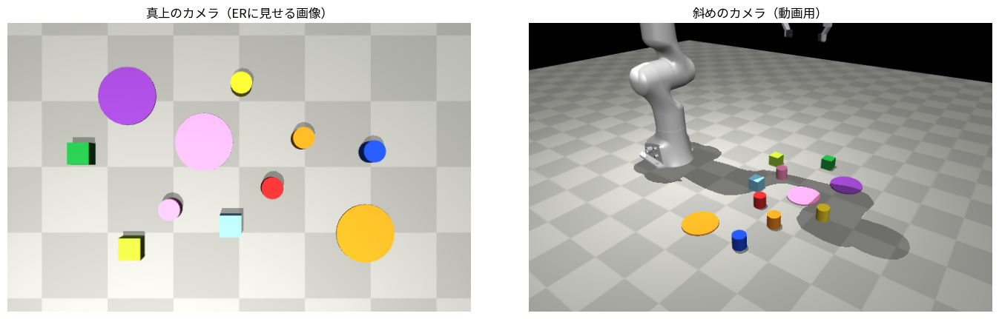

In [38]:
print("mujoco", mujoco.__version__)
objs, targets = get_scene(SCENE_CANDIDATES[0])
env = PickPlaceEnv(objs)
m = env.model
print("nq, nv, nu =", m.nq, m.nv, m.nu, "/ 物体の数:", len(objs))
print("待機姿勢の指先の位置:", env.tcp().round(3), " 手先のz軸:", env.R_down[:, 2].round(2))
print("調整前の明るさの比（写った色 / 本来の色）:", round(measure_gain(env), 2))
top, side = env.render_clear("top"), env.render("side")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), constrained_layout=True)
axes[0].imshow(top); axes[0].set_title("真上のカメラ（ERに見せる画像）"); axes[1].imshow(side); axes[1].set_title("斜めのカメラ（動画用）")
for a in axes: a.axis("off")
plt.show()
env.close()

照明が強いと、色が白っぽく写る。最初に試したときは、ER が色を取り違えて、色で指す指示まで外れた。そこで、画像の色を測って、本来の色に近くなるよう照明の強さを自動で調整する。調整した倍率はセッションに保存し、以降の画像と動画に同じ照明を使う。

照明の倍率 = 0.689（[倍率, 明るさの比] の履歴: [(1.0, 1.415), (0.6888, 0.978)]）


,種類,形,色,本来のRGB,写ったRGB,明るさの比
0,plate,plate,ピンク,"(245, 140, 190)","(238, 136, 185)",0.97
1,plate,plate,オレンジ,"(245, 140, 30)","(239, 137, 29)",0.98
2,plate,plate,紫,"(130, 60, 170)","(121, 56, 158)",0.93
3,block,cylinder,ピンク,"(245, 140, 190)","(252, 144, 196)",1.03
4,block,cylinder,黄,"(245, 215, 40)","(223, 196, 36)",0.91
5,block,cube,水色,"(130, 210, 245)","(134, 216, 253)",1.03
6,block,cylinder,オレンジ,"(245, 140, 30)","(229, 131, 28)",0.94
7,block,cylinder,青,"(30, 70, 215)","(27, 64, 197)",0.92
8,block,cube,黄緑,"(160, 210, 50)","(169, 223, 53)",1.06
9,block,cylinder,赤,"(215, 40, 40)","(213, 39, 39)",0.99


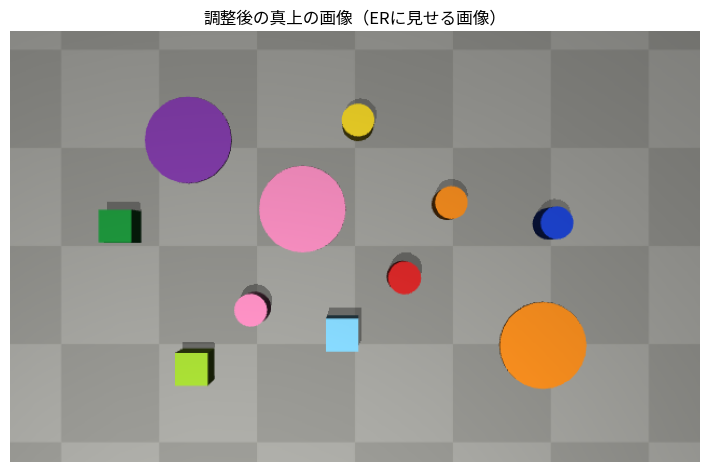

In [39]:
info = prepare_light()

objs, targets = get_scene(SCENE_CANDIDATES[0]); env = PickPlaceEnv(objs)
im = env.render_clear("top").astype(int); rows = []
for o in objs:
    u, v = (int(round(t)) for t in world_to_pixel(o.X, o.Y, 2 * BLOCK_H if o.kind == "block" else 0.004))
    seen = im[v-3:v+4, u-3:u+4].reshape(-1, 3).mean(0); want = np.array(COLORS[o.color])
    rows.append({"種類": o.kind, "形": o.shape, "色": o.color, "本来のRGB": tuple(want),
                 "写ったRGB": tuple(int(x) for x in seen), "明るさの比": round(seen.mean() / want.mean(), 2)})
display(pd.DataFrame(rows))
plt.figure(figsize=(9, 5.6)); plt.imshow(im.astype(np.uint8)); plt.axis("off"); plt.title("調整後の真上の画像（ERに見せる画像）"); plt.show()
env.close()

## 7. シーンの選定

正解の座標で全10個の目標を実行し、成功率が90%以上のシーンだけを使う。ブロックが詰まった配置では、掴むときに周りに当たって、ER とは関係なく失敗することがあるため、先に取り除く。結果はセッションに保存するので、やり直しても同じシーンが選ばれる。

In [40]:
SEEDS = select_scenes(N_SCENES)
print("使うシーン:", SEEDS)

  seed=0: 正解座標での成功率 100% → 採用
  seed=1: 正解座標での成功率 100% → 採用
  seed=2: 正解座標での成功率 100% → 採用
使うシーン: [0, 1, 2]


## 8. ER への問い合わせ

1回の問い合わせで、1つのシーンの10個の指示をまとめて聞く。3種類の指示で、画像と目標は同じ。API の回数は、シーン数 × 3 になる。

済み 0/9、これから 9回（約 1.9 分）
  seed=0 普通の指示 完了
  seed=0 日常会話の指示 完了
  seed=0 複雑な指示 完了
  seed=1 普通の指示 完了
  seed=1 日常会話の指示 完了
  seed=1 複雑な指示 完了
  seed=2 普通の指示 完了
  seed=2 日常会話の指示 完了
  seed=2 複雑な指示 完了
保存済み 9/9


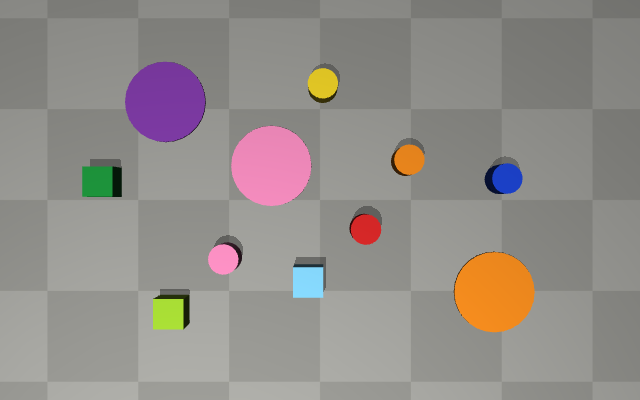

In [41]:
run_er(SEEDS, reps=REPS)
display(scene_image(SEEDS[0]))

## 9. 結果

ER が答えた点でシミュレータを動かし、指示の種類ごとの成功率を比べる。表の「正解座標」は、ER を使わず、正解の位置を直接与えたときの結果で、制御と物理だけで決まる成功率にあたる。

,件数,認識OK,把持OK,運搬OK,成功,95%区間
指示の種類,,,,,,
普通の指示,30,100%,100%,100%,100%,0.89-1.00
日常会話の指示,30,100%,100%,100%,100%,0.89-1.00
複雑な指示,30,87%,87%,87%,87%,0.70-0.95
（参考）正解座標,30,100%,100%,100%,100%,-


,目標の数,成功率(前者),成功率(後者),前者だけ成功,後者だけ成功,p値(McNemar)
比較,,,,,,
普通の指示 と 日常会話の指示,30,100%,100%,0,0,1.000
普通の指示 と 複雑な指示,30,100%,87%,4,0,0.125
日常会話の指示 と 複雑な指示,30,100%,87%,4,0,0.125


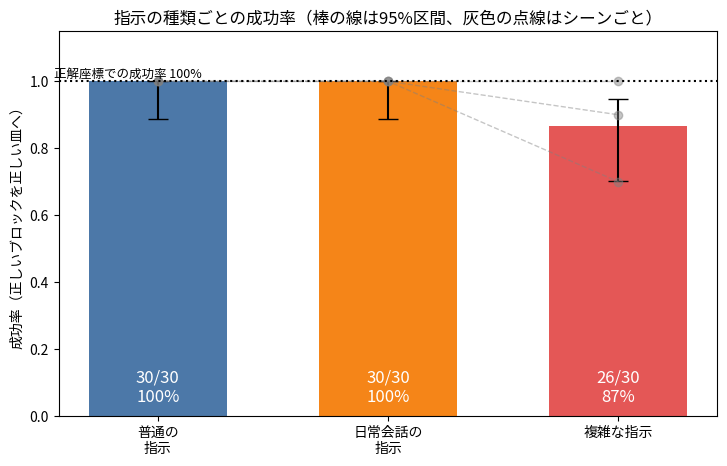

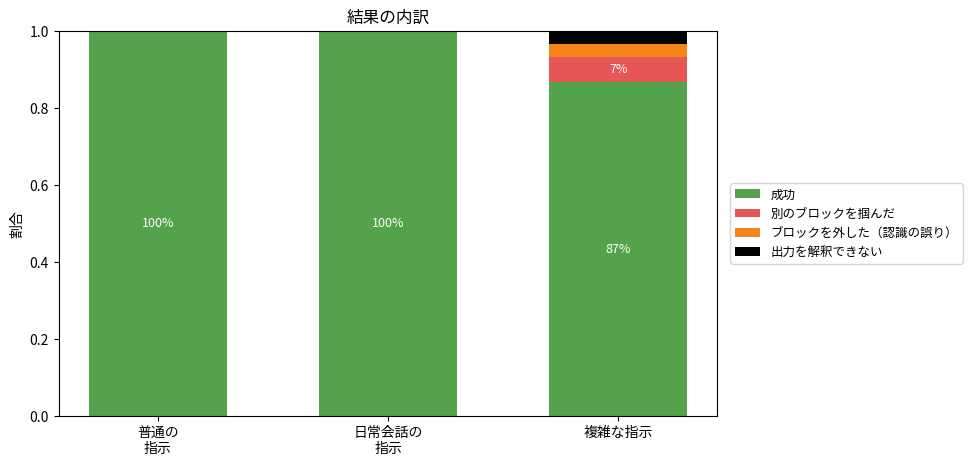

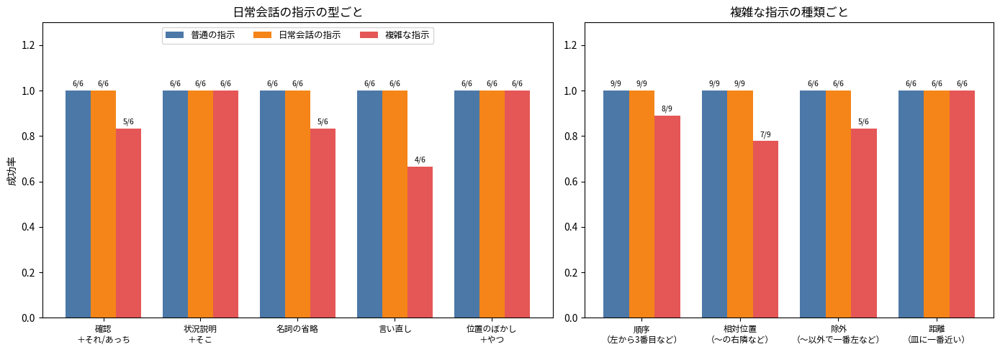

保存:
  /content/drive/MyDrive/gemini_robotics_sessions/run04/plots/01_success_by_kind.png
  /content/drive/MyDrive/gemini_robotics_sessions/run04/plots/02_failure_breakdown.png
  /content/drive/MyDrive/gemini_robotics_sessions/run04/plots/03_breakdown.png
  /content/drive/MyDrive/gemini_robotics_sessions/run04/results/results_all.csv


In [42]:
df, df_or = evaluate(SEEDS, reps=REPS)
report(df, df_or)

## 10. 指示文と個別の実行結果

各シーンで使用したすべての指示文と、それぞれの実行結果を一覧にする。

指示の種類、実際に与えた指示文、正解の操作対象と移動先、認識結果、最終的な成功・失敗、および失敗した場合の原因を確認する。

これにより、どのような表現の指示で失敗が発生したのか、また、失敗が認識・把持・運搬・設置のどの段階に関係しているのかを個別に確認する。

In [51]:
# ===================== 指示文と個別の実行結果 =====================

# 評価結果をコピー（元のdfは変更しない）
detail = df.copy()

# 指示の種類
detail["指示の種類"] = detail["kind"].map(KIND_DESC)

# 複雑な指示の分類
detail["指示の分類"] = detail["cat"].map(CAT_DESC)

# 実際に与えた指示文
detail["実際の指示文"] = detail["instruction"]

# 正解の操作対象と移動先
detail["正解のブロック"] = detail["tb"].map(blk)
detail["正解の皿"] = detail["tw"].map(pl)

# 認識結果
detail["ブロック認識"] = np.where(
    detail["point_ok_block"], "OK", "NG"
)
detail["皿認識"] = np.where(
    detail["point_ok_plate"], "OK", "NG"
)

# 最終結果
detail["最終結果"] = np.where(
    detail["success"], "成功", "失敗"
)

# 失敗原因（成功の場合は空欄）
detail["失敗原因"] = detail.apply(
    lambda r: "" if r["success"] else CLS_JA.get(r["cls"], r["cls"]),
    axis=1
)

# 表示する列を整理
detail_table = detail[
    [
        "seed",
        "idx",
        "kind",
        "指示の種類",
        "指示の分類",
        "実際の指示文",
        "正解のブロック",
        "正解の皿",
        "ブロック認識",
        "皿認識",
        "最終結果",
        "失敗原因",
    ]
].copy()

# 列名を日本語に統一
detail_table = detail_table.rename(columns={
    "seed": "シーン番号",
    "idx": "目標番号",
    "kind": "指示番号",
})

# シーン・指示の種類・目標番号の順に並べる
detail_table = detail_table.sort_values(
    ["シーン番号", "指示番号", "目標番号"]
).reset_index(drop=True)

# 全指示の一覧を先頭5行のみ表示
print(f"評価した指示の総数：{len(detail_table)}件")
display(detail_table.head(5))

# 失敗した指示のみをすべて表示
failure_table = detail_table[
    detail_table["最終結果"] == "失敗"
].copy()

print(f"失敗した指示：{len(failure_table)}件")
display(failure_table)

# 指示の種類ごとの成功・失敗件数も表示
detail_summary = (
    detail_table
    .groupby("指示の種類")["最終結果"]
    .value_counts()
    .unstack(fill_value=0)
)

print("指示の種類ごとの成功・失敗件数")
display(detail_summary)

評価した指示の総数：90件


,シーン番号,目標番号,指示番号,指示の種類,指示の分類,実際の指示文,正解のブロック,正解の皿,ブロック認識,皿認識,最終結果,失敗原因
0,0,1,1,普通の指示,順序（左から3番目など）,黄緑色のブロックをオレンジ色の皿に置いて。,黄緑色のブロック,オレンジ色の皿,OK,OK,成功,
1,0,2,1,普通の指示,除外（〜以外で一番左など）,ピンク色のブロックをオレンジ色の皿に置いて。,ピンク色のブロック,オレンジ色の皿,OK,OK,成功,
2,0,3,1,普通の指示,相対位置（〜の右隣など）,オレンジ色のブロックをピンク色の皿に置いて。,オレンジ色のブロック,ピンク色の皿,OK,OK,成功,
3,0,4,1,普通の指示,相対位置（〜の右隣など）,ピンク色のブロックを紫色の皿に置いて。,ピンク色のブロック,紫色の皿,OK,OK,成功,
4,0,5,1,普通の指示,除外（〜以外で一番左など）,赤いブロックをピンク色の皿に置いて。,赤いブロック,ピンク色の皿,OK,OK,成功,


失敗した指示：4件


,シーン番号,目標番号,指示番号,指示の種類,指示の分類,実際の指示文,正解のブロック,正解の皿,ブロック認識,皿認識,最終結果,失敗原因
57,1,8,3,複雑な指示,相対位置（〜の右隣など）,赤いブロックの右隣のブロックを茶色の皿に置いて。,青いブロック,茶色の皿,NG,NG,失敗,出力を解釈できない
81,2,2,3,複雑な指示,順序（左から3番目など）,左から3番目のブロックをオレンジ色の皿に置いて。,青いブロック,オレンジ色の皿,NG,OK,失敗,別のブロックを掴んだ
83,2,4,3,複雑な指示,相対位置（〜の右隣など）,紫色のブロックの右隣のブロックをオレンジ色の皿に置いて。,赤いブロック,オレンジ色の皿,NG,OK,失敗,ブロックを外した（認識の誤り）
86,2,7,3,複雑な指示,除外（〜以外で一番左など）,ピンク色のブロックと黄緑色のブロック以外で、一番右のブロックを黄色い皿に置いて。,水色のブロック,黄色い皿,NG,OK,失敗,別のブロックを掴んだ


指示の種類ごとの成功・失敗件数


最終結果,失敗,成功
指示の種類,,
日常会話の指示,0,30
普通の指示,0,30
複雑な指示,4,26


## 11. 動画

指示の種類ごとに1本、計3本を作る。3本とも同じ目標を使うので、同じ動作を3種類の指示で見比べられる。左の画像の赤い×と青い丸が、ER が指したブロックと皿の位置。上に指示文と動作の段階、最後に結果を出す。

In [47]:
videos = make_videos_by_kind(
    df,
    k=EPISODES_PER_VIDEO,
    rep=0
)

for v in videos:
    n_success = sum(r["success"] for r in v["results"])
    n_failure = len(v["results"]) - n_success

    print(
        f"{KIND_DESC[v['kind']]}：成功 {n_success} 件、失敗 {n_failure} 件"
    )

if SHOW_VIDEOS:
    for v in videos:
        display(Video(v["path"], embed=True, width=720))

普通の指示：成功 4 件、失敗 0 件
日常会話の指示：成功 4 件、失敗 0 件
複雑な指示：成功 2 件、失敗 2 件


In [49]:
# コード実行中にDrive上で動画の名称を変更したため、上記セルでは正しく出力されていない。
if SHOW_VIDEOS:
    for v in videos:
        display(Video(v["path"], embed=True, width=720))

# 最後の複雑な指示では、解釈ができなかった失敗を採用してしまっているため、動画が作成されない。